In [130]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [131]:
df = pd.read_csv("https://catalog.ourworldindata.org/emissions/owid_co2/owid_co2.csv")

In [132]:
import os
os.makedirs("data", exist_ok=True)
df.to_csv("data/owid_co2_raw.csv", index=False)
print("Saved:", df.shape)

Saved: (56269, 79)


## Questions I Want to Answer
1. How have global CO2 emissions changed between 1965 and 2022?
2. Which countries are the top emitters in total CO2, and which are the top in per-capita CO2?
3. Do countries with a higher GDP also emit more CO2? (correlation)
4. Which fuel source (coal, oil, gas, cement) contributes the most to CO2 emissions?
5. Did emissions really fall in 2020 because of COVID-19?
6. Do wealthy countries (high GDP per capita) emit more CO2 per person than poorer countries?
7. Which columns have the most missing data, and where are the outliers and anomalies?

## Data Structure

In [133]:
print(df.shape)
display(df.head())
display(df.tail())

(56269, 79)


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_energy_supply,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,"2,802,560.00",NaN,0.00,0.00,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.00,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_energy_supply,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
56264,Zimbabwe,2021,ZWE,"15,797,220.00","25,140,088,767.00",0.42,0.03,10.13,1.70,20.10,...,0.10,0.00,0.00,0.00,0.00,36.87,27.91,16.41,3.56,35.19
56265,Zimbabwe,2022,ZWE,"16,069,061.00","25,901,585,881.00",0.36,0.02,12.26,2.13,20.99,...,0.10,0.00,0.00,0.00,0.00,57.51,29.92,18.83,2.56,20.86
56266,Zimbabwe,2023,ZWE,"16,340,829.00",NaN,0.40,0.02,15.10,2.84,23.17,...,0.10,0.00,0.00,0.00,0.00,53.66,31.03,20.32,1.04,6.88
56267,Zimbabwe,2024,ZWE,"16,634,366.00",NaN,0.40,0.02,15.21,0.11,0.73,...,0.10,0.00,0.00,0.00,0.00,67.52,31.07,20.77,0.93,6.12
56268,Zimbabwe,2025,ZWE,"16,950,798.00",NaN,0.40,0.02,17.35,2.14,14.08,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [134]:
print("First year:", df["year"].min())
print("Last year:", df["year"].max())
print("Unique years:", df["year"].nunique())

First year: 1750
Last year: 2025
Unique years: 276


There are total 276 unique year values registered

In [135]:
print("Unique countries/regions:", df["country"].nunique())
print(df["country"].unique())

Unique countries/regions: 259
['Afghanistan' 'Africa' 'Africa (GCP)' 'Albania' 'Algeria' 'Andorra'
 'Angola' 'Anguilla' 'Antarctica' 'Antigua and Barbuda' 'Argentina'
 'Armenia' 'Aruba' 'Asia' 'Asia (GCP)' 'Asia (excl. China and India)'
 'Australia' 'Austria' 'Azerbaijan' 'Bahamas' 'Bahrain' 'Bangladesh'
 'Barbados' 'Belarus' 'Belgium' 'Belize' 'Benin' 'Bermuda' 'Bhutan'
 'Bolivia' 'Bonaire Sint Eustatius and Saba' 'Bosnia and Herzegovina'
 'Botswana' 'Brazil' 'British Virgin Islands' 'Brunei' 'Bulgaria'
 'Burkina Faso' 'Burundi' 'Cambodia' 'Cameroon' 'Canada' 'Cape Verde'
 'Central African Republic' 'Central America (GCP)' 'Chad' 'Chile' 'China'
 'Christmas Island' 'Colombia' 'Comoros' 'Congo' 'Cook Islands'
 'Costa Rica' "Cote d'Ivoire" 'Croatia' 'Cuba' 'Curacao' 'Cyprus'
 'Czechia' 'Democratic Republic of Congo' 'Denmark' 'Djibouti' 'Dominica'
 'Dominican Republic' 'East Timor' 'Ecuador' 'Egypt' 'El Salvador'
 'Equatorial Guinea' 'Eritrea' 'Estonia' 'Eswatini' 'Ethiopia' 'Europe'
 '

In [136]:
display(df[["country", "iso_code"]].head(20))
print("Missing iso_code:", df["iso_code"].isna().sum())

,country,iso_code
0,Afghanistan,AFG
1,Afghanistan,AFG
2,Afghanistan,AFG
3,Afghanistan,AFG
4,Afghanistan,AFG
5,Afghanistan,AFG
6,Afghanistan,AFG
7,Afghanistan,AFG
8,Afghanistan,AFG
9,Afghanistan,AFG


Missing iso_code: 7963


7,963 rows have no iso_code. They belong to 36 non-country entities (regions, income groups, World, aviation/shipping), not to real countries.

## Cleaning and Preparation

In [137]:
df_countries = df[df["iso_code"].notna()]
df_nocode = df[df["iso_code"].isna()]

print(len(df), len(df_countries), len(df_nocode))
print(df_countries["country"].nunique())
print(df_nocode["country"].nunique())
print(sorted(df_nocode["country"].unique()))

56269 48306 7963
223
36
['Africa', 'Africa (GCP)', 'Asia', 'Asia (GCP)', 'Asia (excl. China and India)', 'Central America (GCP)', 'Europe', 'Europe (GCP)', 'Europe (excl. EU-27)', 'Europe (excl. EU-28)', 'European Union (27)', 'European Union (28)', 'High-income countries', 'International aviation', 'International shipping', 'Kosovo', 'Kuwaiti Oil Fires', 'Kuwaiti Oil Fires (GCP)', 'Least developed countries (Jones et al.)', 'Low-income countries', 'Lower-middle-income countries', 'Middle East (GCP)', 'Non-OECD (GCP)', 'North America', 'North America (GCP)', 'North America (excl. USA)', 'OECD (GCP)', 'OECD (Jones et al.)', 'Oceania', 'Oceania (GCP)', 'Ryukyu Islands', 'Ryukyu Islands (GCP)', 'South America', 'South America (GCP)', 'Upper-middle-income countries', 'World']


Separating actual countries from regional groups

In [138]:
owid_like = df_countries[df_countries["iso_code"].str.startswith("OWID")]
print(owid_like[["country", "iso_code"]].drop_duplicates())

Empty DataFrame
Columns: [country, iso_code]
Index: []


There is no row which starts with "OWID"

In [139]:
df_main = df_countries[
    (df_countries["year"] >= 1965) & (df_countries["year"] <= 2022)
].copy()

print(df_main.shape)
print(df_main["year"].min(), df_main["year"].max())
print(df_main["country"].nunique())

(12934, 79)
1965 2022
223


Filtered to keep from 1965-2022

In [140]:
num_cols = df_main.select_dtypes(include="number").columns
cat_cols = df_main.select_dtypes(exclude="number").columns
print("Numeric columns:", len(num_cols))
print("Categorical columns:", list(cat_cols))

Numeric columns: 77
Categorical columns: ['country', 'iso_code']


In [141]:
years_per_country = df_main.groupby("country")["year"].count()
print(years_per_country.describe())
print(years_per_country[years_per_country < 58].sort_values().head(15))

count   223.00
mean     58.00
std       0.00
min      58.00
25%      58.00
50%      58.00
75%      58.00
max      58.00
Name: year, dtype: float64
Series([], Name: year, dtype: int64)


Every country has all 58 years (223 × 58 = 12,934 rows), so missingness is in values, not in missing rows.

In [142]:
df_main.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12934 entries, 215 to 56265
Data columns (total 79 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   country                                    12934 non-null  object 
 1   year                                       12934 non-null  int64  
 2   iso_code                                   12934 non-null  object 
 3   population                                 12818 non-null  float64
 4   gdp                                        9264 non-null   float64
 5   cement_co2                                 12086 non-null  float64
 6   cement_co2_per_capita                      11975 non-null  float64
 7   co2                                        12343 non-null  float64
 8   co2_growth_abs                             12320 non-null  float64
 9   co2_growth_prct                            12274 non-null  float64
 10  co2_including_luc        

In [143]:
pd.options.display.float_format = "{:,.2f}".format

print(df_main.dtypes.value_counts())
print(df_main[["population", "gdp", "co2", "co2_per_capita"]].describe())

float64    76
object      2
int64       1
Name: count, dtype: int64
            population                   gdp       co2  co2_per_capita
count        12,818.00              9,264.00 12,343.00       12,264.00
mean     25,461,194.59    362,068,934,959.15    111.92            5.31
std     106,749,539.23  1,370,696,524,943.06    552.21           12.37
min             513.00         76,992,000.00      0.00            0.00
25%         415,845.00     12,094,961,529.25      0.60            0.53
50%       4,328,853.00     41,717,783,729.00      5.32            2.33
75%      14,398,480.50    195,564,769,245.75     43.16            6.77
max   1,426,437,269.00 26,966,016,991,166.00 11,695.01          406.30


co2_per_capita has a mean of 5.31 but a median of 2.33, and a maximum of 406.30 against a 75th percentile of 6.77. The same skew appears in co2, population and gdp, so I use medians, log scales and non-parametric tests.

In [144]:
print(df_main.nlargest(5, "co2_per_capita")[["country", "year", "co2_per_capita", "population"]])

                         country  year  co2_per_capita   population
46157  Sint Maarten (Dutch part)  1965          406.30     4,304.00
46159  Sint Maarten (Dutch part)  1967          392.00     5,090.00
46158  Sint Maarten (Dutch part)  1966          367.21     4,683.00
27196                     Kuwait  1991          364.85 1,351,403.00
46161  Sint Maarten (Dutch part)  1969          352.93     5,970.00


## Data Quality Issues

In [145]:
missing_pct = (df_main.isna().mean() * 100).sort_values(ascending=False).round(1)
print(missing_pct.head(25))

share_global_cumulative_other_co2     88.30
share_global_other_co2                88.30
cumulative_other_co2                  87.60
other_industry_co2                    87.60
other_co2_per_capita                  87.60
consumption_co2_per_gdp               69.80
trade_co2_share                       69.50
trade_co2                             69.50
consumption_co2_per_capita            69.50
consumption_co2                       69.50
cumulative_gas_co2                    50.20
share_global_cumulative_gas_co2       50.20
share_global_gas_co2                  50.20
gas_co2                               50.20
gas_co2_per_capita                    50.20
energy_per_gdp                        39.90
coal_co2                              37.00
coal_co2_per_capita                   37.00
cumulative_coal_co2                   37.00
share_global_coal_co2                 37.00
share_global_cumulative_coal_co2      37.00
flaring_co2_per_capita                35.90
share_global_cumulative_flaring_

In [146]:
key_cols = [
    "population", "gdp", "co2", "co2_per_capita", "energy_per_capita",
    "coal_co2", "oil_co2", "gas_co2", "cement_co2", "methane", "total_ghg"
]
print(missing_pct[key_cols])

population           0.90
gdp                 28.40
co2                  4.60
co2_per_capita       5.20
energy_per_capita   25.60
coal_co2            37.00
oil_co2              5.20
gas_co2             50.20
cement_co2           6.60
methane             10.80
total_ghg           10.80
dtype: float64


calculating the percentage of missing data for each column and checking

In [147]:
print(df_main.duplicated().sum())
print(df_main.duplicated(subset=["country", "year"]).sum())

0
0


No duplicate year

In [148]:
cols_over_50 = missing_pct[missing_pct > 50]
print(len(cols_over_50), "columns have >50% missing")
print(cols_over_50.head(20))

15 columns have >50% missing
share_global_cumulative_other_co2   88.30
share_global_other_co2              88.30
cumulative_other_co2                87.60
other_industry_co2                  87.60
other_co2_per_capita                87.60
consumption_co2_per_gdp             69.80
trade_co2_share                     69.50
trade_co2                           69.50
consumption_co2_per_capita          69.50
consumption_co2                     69.50
cumulative_gas_co2                  50.20
share_global_cumulative_gas_co2     50.20
share_global_gas_co2                50.20
gas_co2                             50.20
gas_co2_per_capita                  50.20
dtype: float64


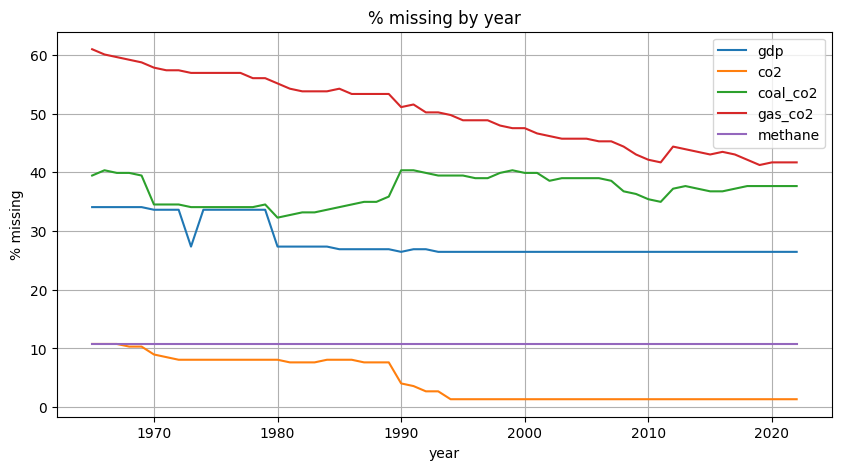

In [149]:
miss_year = df_main.groupby("year")[["gdp", "co2", "coal_co2", "gas_co2", "methane"]] \
                   .apply(lambda g: g.isna().mean() * 100)

miss_year.plot(figsize=(10, 5))
plt.title("% missing by year")
plt.ylabel("% missing")
plt.grid(True)
plt.show()

Data availability improves significantly in later years, showing a much higher density and continuity of records over time compared to earlier decades.

In [150]:
num = df_main.select_dtypes(include="number")
neg = (num < 0).sum()
print(neg[neg > 0])

co2_growth_abs                               3900
co2_growth_prct                              3900
co2_including_luc                             172
co2_including_luc_growth_abs                 4910
co2_including_luc_growth_prct                4976
co2_including_luc_per_capita                  172
co2_including_luc_per_gdp                     127
co2_including_luc_per_unit_energy             108
cumulative_co2_including_luc                  113
cumulative_luc_co2                            823
ghg_per_capita                                 55
land_use_change_co2                          2894
land_use_change_co2_per_capita               2782
share_global_co2_including_luc                172
share_global_cumulative_co2_including_luc     113
share_global_cumulative_luc_co2               823
share_global_luc_co2                         2894
share_of_temperature_change_from_ghg           54
temperature_change_from_ch4                    88
temperature_change_from_co2                   141


Negative values in growth and land-use are legitimate (representing carbon sinks or emission decreases). They have been kept as-is since they accurately reflect real-world environmental data.

In [151]:
chk = df_main[["co2", "population", "co2_per_capita"]].dropna()
calc = chk["co2"] * 1e6 / chk["population"]
bad = ((calc - chk["co2_per_capita"]).abs() / chk["co2_per_capita"].replace(0, np.nan) > 0.05).mean()
print(f"{bad * 100:.2f}% rows - co2_per_capita and (co2 / population) doesnt match")

0.00% rows - co2_per_capita and (co2 / population) doesnt match


In [152]:
cols_to_drop = missing_pct[missing_pct > 80].index
print("Dropping:", list(cols_to_drop))
df_clean = df_main.drop(columns=cols_to_drop)
print(df_main.shape, "->", df_clean.shape)
df_main = df_clean.copy()
df_main.to_csv("owid_co2_clean.csv", index=False)

Dropping: ['share_global_cumulative_other_co2', 'share_global_other_co2', 'cumulative_other_co2', 'other_industry_co2', 'other_co2_per_capita']
(12934, 79) -> (12934, 74)


## Trends, Patterns, Anomalies

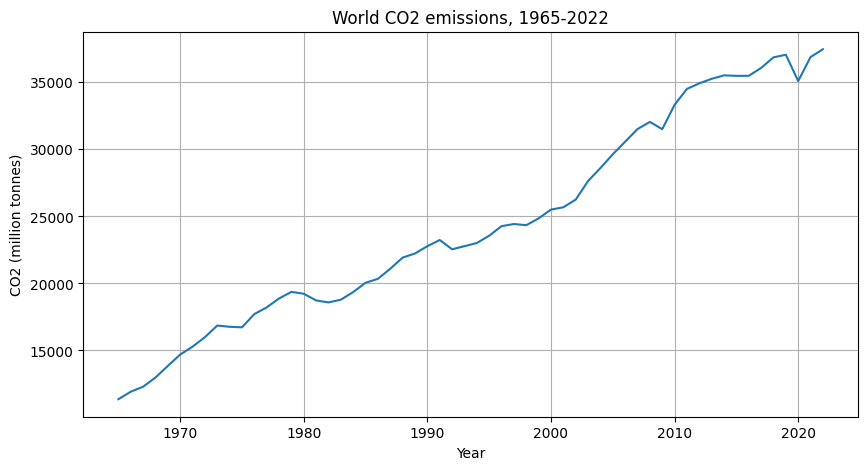

In [153]:
world = df[(df["country"] == "World") & (df["year"].between(1965, 2022))]

plt.figure(figsize=(10, 5))
plt.plot(world["year"], world["co2"])
plt.title("World CO2 emissions, 1965-2022")
plt.xlabel("Year")
plt.ylabel("CO2 (million tonnes)")
plt.grid(True)
plt.show()

World CO2 rose in almost every year between 1965 and 2022, with a few short dips.

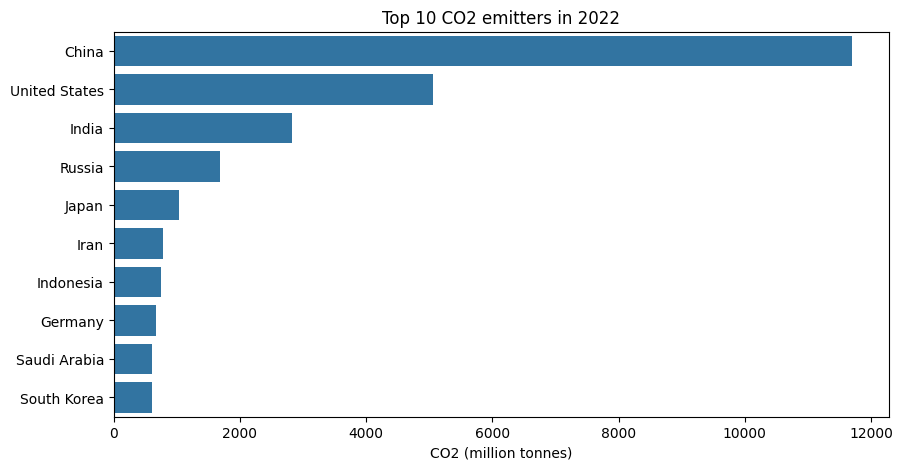

In [154]:
latest = df_main[df_main["year"] == 2022].nlargest(10, "co2")

plt.figure(figsize=(10, 5))
sns.barplot(data=latest, x="co2", y="country")
plt.title("Top 10 CO2 emitters in 2022")
plt.xlabel("CO2 (million tonnes)")
plt.ylabel("")
plt.show()

In 2022, China was the largest total CO2 emitter by a wide margin, emitting more than double the amount of the second-largest emitter, the United States.

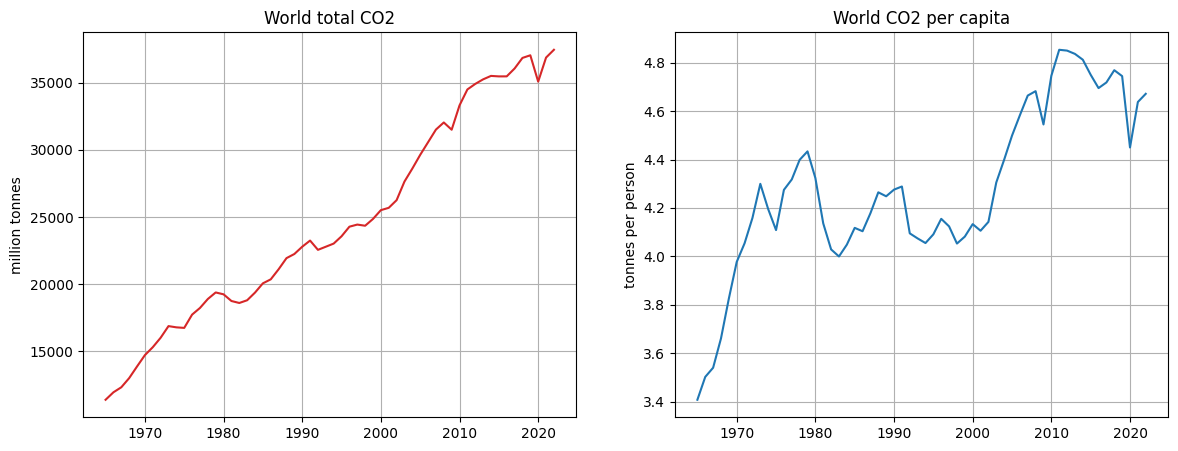

In [155]:
world = df[(df["country"] == "World") & (df["year"].between(1965, 2022))]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(world["year"], world["co2"], color="tab:red")
ax[0].set_title("World total CO2")
ax[0].set_ylabel("million tonnes")
ax[1].plot(world["year"], world["co2_per_capita"], color="tab:blue")
ax[1].set_title("World CO2 per capita")
ax[1].set_ylabel("tonnes per person")
for a in ax: a.grid(True)
plt.show()

While total global CO2 rose steadily from 1965 to 2022, per-capita emissions leveled off in recent years, showing a noticeable temporary dip in 2020 during the COVID-19 pandemic.

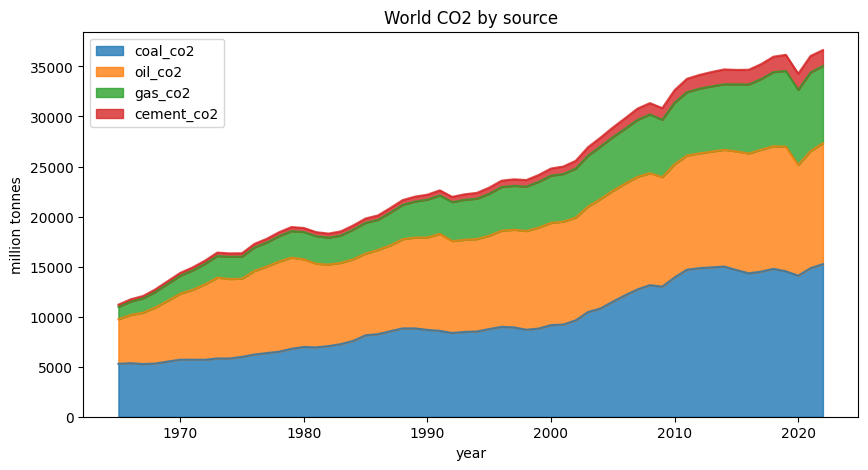

In [156]:
fuels = ["coal_co2", "oil_co2", "gas_co2", "cement_co2"]
world.set_index("year")[fuels].plot.area(figsize=(10, 5), alpha=0.8)
plt.title("World CO2 by source")
plt.ylabel("million tonnes")
plt.show()

Coal and oil make up the largest share of global CO2 emissions, while natural gas has expanded rapidly since the 1970s to become the third-largest contributor.

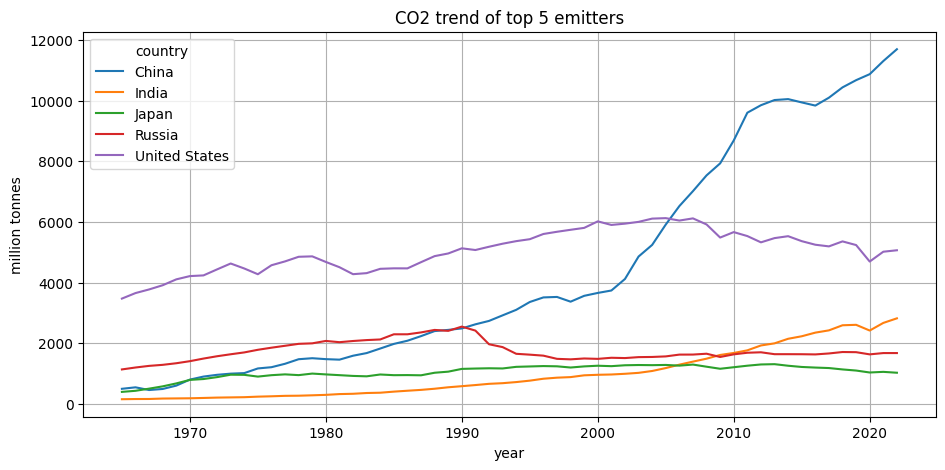

In [157]:
top5 = df_main[df_main["year"] == 2022].nlargest(5, "co2")["country"]

plt.figure(figsize=(11, 5))
sns.lineplot(data=df_main[df_main["country"].isin(top5)], x="year", y="co2", hue="country")
plt.title("CO2 trend of top 5 emitters")
plt.ylabel("million tonnes")
plt.grid(True)
plt.show()

China's emissions surged dramatically after 2000, surpassing the US around 2006 to become the world's largest emitter, while US emissions began slowly declining and India rose steadily.

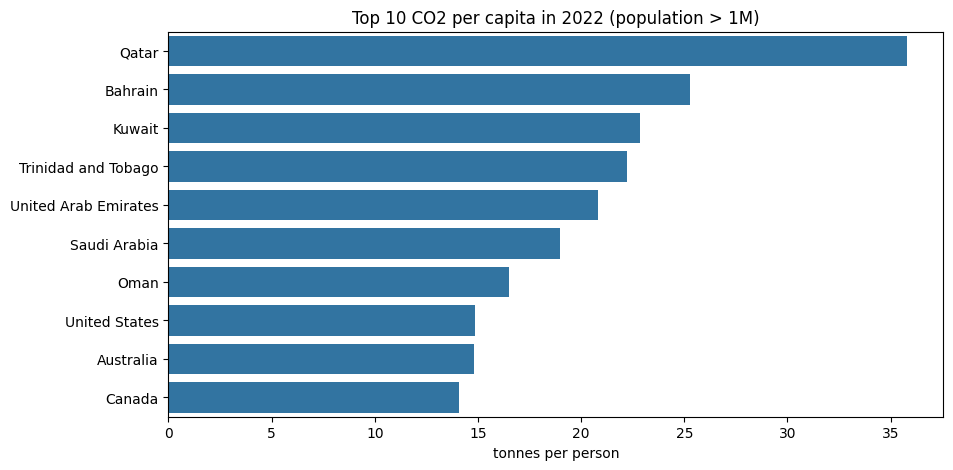

In [158]:
pc = df_main[(df_main["year"] == 2022) & (df_main["population"] > 1_000_000)].nlargest(10, "co2_per_capita")

plt.figure(figsize=(10, 5))
sns.barplot(data=pc, x="co2_per_capita", y="country")
plt.title("Top 10 CO2 per capita in 2022 (population > 1M)")
plt.xlabel("tonnes per person")
plt.ylabel("")
plt.show()

Oil- and gas-producing Gulf nations dominate per-capita emissions, with Qatar leading at over 35 tonnes per person—more than double that of the United States.

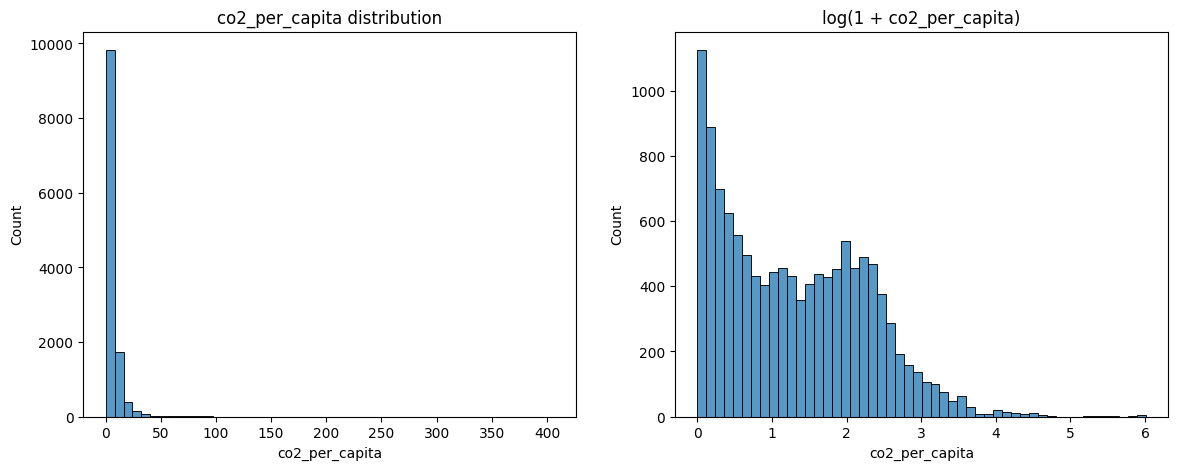

In [159]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_main["co2_per_capita"].dropna(), bins=50, ax=ax[0])
ax[0].set_title("co2_per_capita distribution")
sns.histplot(np.log1p(df_main["co2_per_capita"].dropna()), bins=50, ax=ax[1])
ax[1].set_title("log(1 + co2_per_capita)")
plt.show()

Raw per-capita CO2 emissions are heavily right-skewed due to a few extreme outliers, whereas applying a log transformation produces a much more balanced, readable distribution.

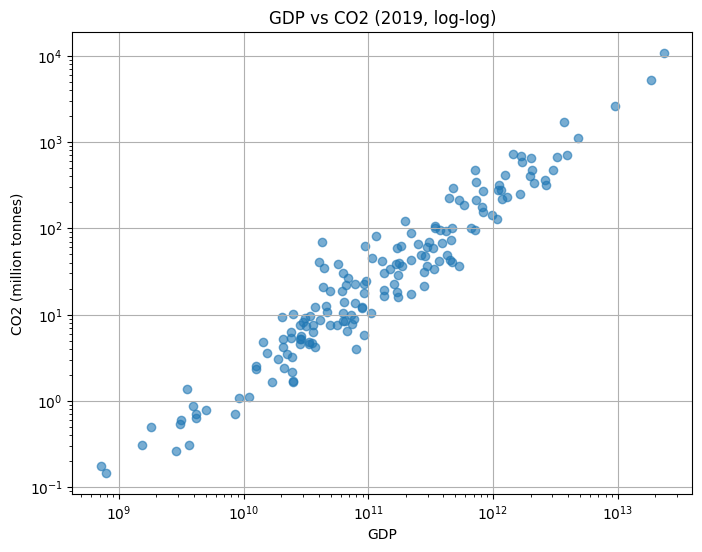

In [160]:
d = df_main[df_main["year"] == 2019][["country", "gdp", "co2"]].dropna()

plt.figure(figsize=(8, 6))
plt.scatter(d["gdp"], d["co2"], alpha=0.6)
plt.xscale("log"); plt.yscale("log")
plt.title("GDP vs CO2 (2019, log-log)")
plt.xlabel("GDP"); plt.ylabel("CO2 (million tonnes)")
plt.grid(True)
plt.show()

There is a strong, positive linear relationship on a log-log scale, confirming that countries with higher economic output (GDP) consistently generate higher total CO2 emissions.

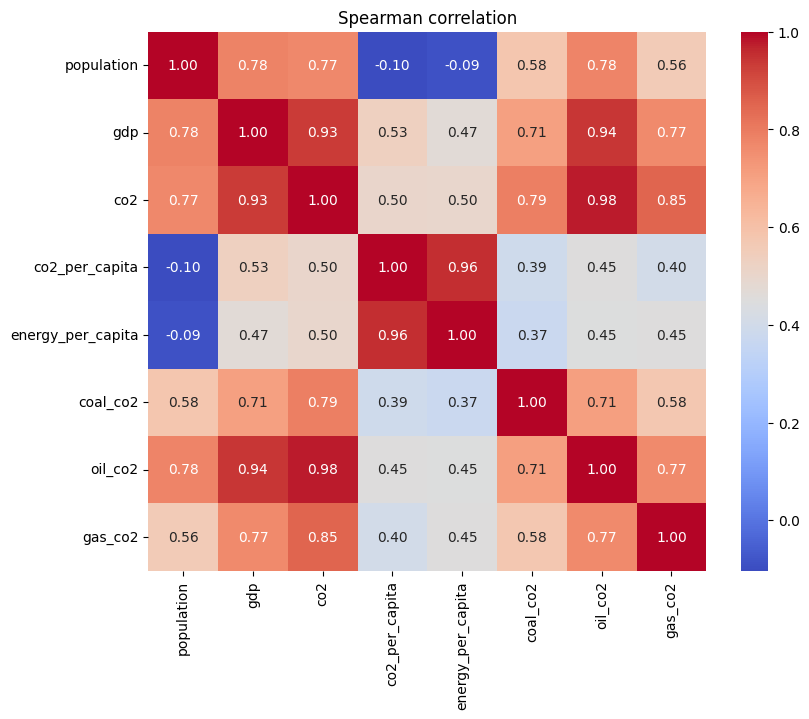

In [161]:
corr_cols = ["population", "gdp", "co2", "co2_per_capita", "energy_per_capita",
             "coal_co2", "oil_co2", "gas_co2"]

plt.figure(figsize=(9, 7))
sns.heatmap(df_main[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Spearman correlation")
plt.show()

Total CO2 strongly correlates with GDP ($r = 0.93$) and fossil fuel sources like oil ($0.98$) and gas ($0.85$), while per-capita CO2 strongly tracks per-capita energy use ($0.96$) rather than population size ($-0.10$).

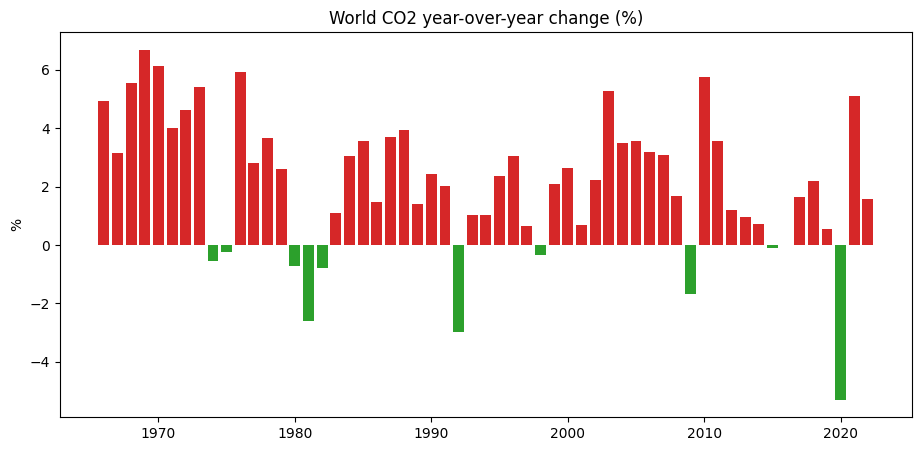

       year       co2  co2_change_pct
55534  2019 37,060.62            0.54
55535  2020 35,095.29           -5.30
55536  2021 36,889.07            5.11


In [162]:
world = world.copy()
world["co2_change_pct"] = world["co2"].pct_change() * 100

plt.figure(figsize=(11, 5))
plt.bar(world["year"], world["co2_change_pct"],
        color=np.where(world["co2_change_pct"] < 0, "tab:green", "tab:red"))
plt.title("World CO2 year-over-year change (%)")
plt.ylabel("%")
plt.show()

print(world.loc[world["year"].isin([2019, 2020, 2021]), ["year", "co2", "co2_change_pct"]])

Global emissions grew in almost every year since 1965, with sharp negative drops aligning with major global shocks like the 1990s Soviet collapse, the 2009 financial crisis, and a record $-5.30\%$ drop during the 2020 COVID-19 pandemic.

In [163]:
df_main = df_main.sort_values(["country", "year"])
df_main["co2_yoy"] = df_main.groupby("country")["co2"].pct_change(fill_method=None) * 100

spikes = df_main[(df_main["co2"] > 10) & (df_main["co2_yoy"].abs() > 40)]
print(spikes[["country", "year", "co2", "co2_yoy"]].sort_values("co2_yoy").to_string())

                    country  year    co2  co2_yoy
27197                Kuwait  1992  30.22   -93.87
28947                 Libya  2020  31.19   -61.74
55706                 Yemen  2015  13.86   -47.87
29275             Lithuania  1992  21.17   -44.03
38192           North Korea  1990 118.38   -43.16
36835               Nigeria  1989  39.83   -41.50
34780               Myanmar  2018  34.23    41.69
24932                  Iraq  1966  26.94    42.03
52876  United Arab Emirates  2000 111.65    42.46
55030               Vietnam  1966  18.45    43.99
51617          Turkmenistan  2021  91.09    44.24
36856               Nigeria  2010 113.19    44.55
1134                Algeria  1980  65.35    45.22
36825               Nigeria  1979  69.41    45.41
42111                 Qatar  1992  25.37    45.68
24942                  Iraq  1976  47.22    46.34
38173           North Korea  1971 107.31    46.38
49407                 Syria  1979  21.10    47.69
36817               Nigeria  1971  31.81    50.44


Most large year-on-year jumps come from oil-dependent or conflict-affected economies (Kuwait, Libya, Iraq, Nigeria, Yemen). They are probably real events, but I did not verify them against outside sources.

                         country  co2_per_capita
42141                      Qatar           35.77
8095                      Brunei           27.32
4732                     Bahrain           25.29
27227                     Kuwait           22.84
50886        Trinidad and Tobago           22.20
52898       United Arab Emirates           20.81
44959               Saudi Arabia           18.97
46214  Sint Maarten (Dutch part)           18.25
35964              New Caledonia           17.72
39755                       Oman           16.49
53450              United States           14.83
3892                   Australia           14.80
9416                      Canada           14.06


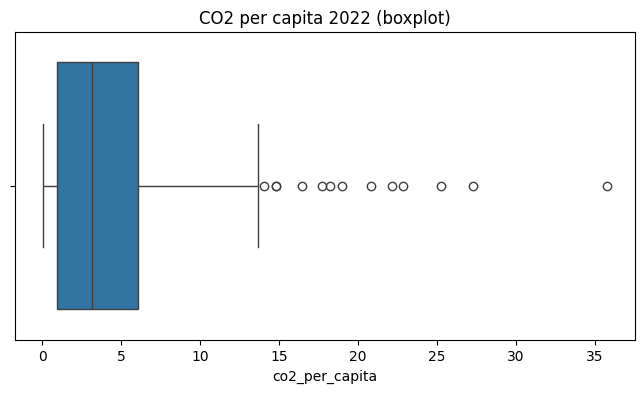

In [164]:
latest = df_main[(df_main["year"] == 2022)]["co2_per_capita"].dropna()
q1, q3 = latest.quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df_main[(df_main["year"] == 2022) &
                   (df_main["co2_per_capita"] > q3 + 1.5 * iqr)][["country", "co2_per_capita"]]
print(outliers.sort_values("co2_per_capita", ascending=False))

plt.figure(figsize=(8, 4))
sns.boxplot(x=latest)
plt.title("CO2 per capita 2022 (boxplot)")
plt.show()

The IQR method flags 13 countries as upper outliers (above ~14 tonnes per person), led by Qatar (35.77) and Brunei (27.32), reflecting heavy fossil fuel production and high per-capita energy consumption rather than data errors.

## Hypothesis Testing + Assumptions


In [165]:
# Assumption check: is the data normally distributed?
d = df_main[df_main["year"] == 2019]["co2_per_capita"].dropna()
print("Skewness raw:", stats.skew(d))
print("Skewness log:", stats.skew(np.log1p(d)))
print("Shapiro raw p-value:", stats.shapiro(d)[1])
print("Shapiro log p-value:", stats.shapiro(np.log1p(d))[1])

Skewness raw: 2.2349563851245704
Skewness log: 0.1980962434291866
Shapiro raw p-value: 2.94917236832039e-17
Shapiro log p-value: 0.00016379874770843718


The raw data is heavily right-skewed ($\text{skewness} = 2.23$) and fails the Shapiro-Wilk normality test ($p < 0.05$). Even after log transformation reduces skewness to $0.20$, it remains non-normal ($p = 0.00016$), justifying the use of non-parametric tests (Spearman, Mann-Whitney U, and Wilcoxon)

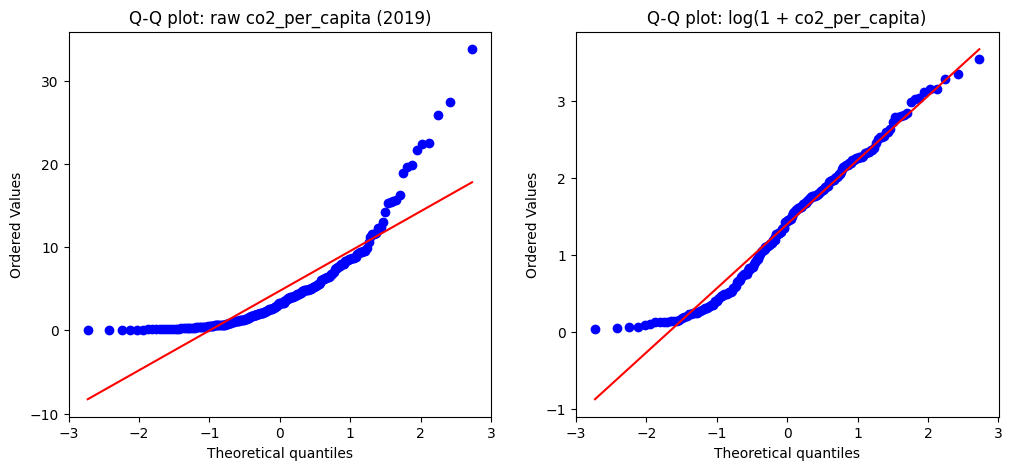

In [166]:
d_qq = df_main[df_main["year"] == 2019]["co2_per_capita"].dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
stats.probplot(d_qq, dist="norm", plot=ax[0])
ax[0].set_title("Q-Q plot: raw co2_per_capita (2019)")
stats.probplot(np.log1p(d_qq), dist="norm", plot=ax[1])
ax[1].set_title("Q-Q plot: log(1 + co2_per_capita)")
plt.show()

For the cell below -

H1 test. H0: GDP and CO2 have no monotonic relationship (rho = 0). H1: rho ≠ 0. Test: Spearman (skewed data), alpha = 0.05.

In [167]:
# H1: GDP and CO2 are positively correlated (H0: no correlation)
# H2: Wealthy countries have higher CO2 per capita than poorer ones
d = df_main[df_main["year"] == 2019][["gdp", "co2"]].dropna()
r, p = stats.spearmanr(d["gdp"], d["co2"])
print(f"Spearman r = {r:.3f}, p-value = {p:.2e}, n = {len(d)}")
print("Reject H0" if p < 0.05 else "Fail to reject H0")

Spearman r = 0.948, p-value = 8.96e-83, n = 164
Reject H0


There is a very strong, statistically significant positive correlation between GDP and total CO2 emissions ($r = 0.948$, $p = 8.96 \times 10^{-83}$). We reject $H_0$, confirming that larger economies produce significantly higher total emissions.

In [168]:
d2 = df_main[df_main["year"] == 2019][["gdp", "population", "co2_per_capita"]].dropna().copy()
d2["gdp_pc"] = d2["gdp"] / d2["population"]
r2, p2 = stats.spearmanr(d2["gdp_pc"], d2["co2_per_capita"])
print(f"GDP per capita vs CO2 per capita: rho = {r2:.3f}, p = {p2:.2e}, n = {len(d2)}")

GDP per capita vs CO2 per capita: rho = 0.907, p = 1.27e-62, n = 164


Total GDP and total CO2 are both large for big countries, so this partly reflects size. The per-capita version removes that effect.

For the cell below -

H2 test. H0: CO2 per capita of above-median GDP-per-capita countries is not higher than the rest. H1: it is higher. Main test: Mann-Whitney U (one-sided). Welch t-test on log values is a robustness check.

In [169]:
# H2: Wealthy countries have higher CO2 per capita than poorer ones
d = df_main[df_main["year"] == 2019][["country", "gdp", "population", "co2_per_capita"]].dropna().copy()
d["gdp_pc"] = d["gdp"] / d["population"]
cut = d["gdp_pc"].median()
rich = d[d["gdp_pc"] >= cut]["co2_per_capita"]
poor = d[d["gdp_pc"] < cut]["co2_per_capita"]

u, p_u = stats.mannwhitneyu(rich, poor, alternative="greater")
t, p_t = stats.ttest_ind(np.log1p(rich), np.log1p(poor), equal_var=False)
print(f"n rich = {len(rich)}, n poor = {len(poor)}")
print(f"Rich: mean = {rich.mean():.2f}, median = {rich.median():.2f}")
print(f"Poor: mean = {poor.mean():.2f}, median = {poor.median():.2f}")
print(f"Mann-Whitney p = {p_u:.2e}")
print(f"Welch t-test (log) p = {p_t:.2e}")

n rich = 82, n poor = 82
Rich: mean = 8.03, median = 6.17
Poor: mean = 1.28, median = 0.80
Mann-Whitney p = 8.64e-25
Welch t-test (log) p = 5.34e-35


Wealthier countries emit over six times more CO2 per capita on average ($8.03$ vs. $1.28$ tonnes), and both the Mann-Whitney U ($p = 8.64 \times 10^{-25}$) and Welch's t-test ($p = 5.34 \times 10^{-35}$) confirm this difference is statistically significant.

For the cell below -

H3 test. H0: 2020 CO2 is not lower than 2019 CO2 for the same country. H1: 2019 is higher than 2020. Test: Wilcoxon signed-rank (paired, one-sided).

In [170]:
# H3: CO2 in 2020 was lower than in 2019 (COVID-19 effect)
p = df_main[df_main["year"].isin([2019, 2020])].pivot(index="country", columns="year", values="co2").dropna()
stat, pv = stats.wilcoxon(p[2019], p[2020], alternative="greater")
print(f"Wilcoxon p = {pv:.2e}, n = {len(p)}")
print(f"{(p[2020] < p[2019]).mean() * 100:.1f}% countries CO2 went down in 2020")

Wilcoxon p = 3.79e-13, n = 220
70.5% countries CO2 went down in 2020


The Wilcoxon signed-rank test confirms a statistically significant drop in emissions from 2019 to 2020 ($p = 3.79 \times 10^{-13}$), with $70.5\%$ of countries reducing their CO2 output during the 2020 COVID-19 lockdowns.

In [171]:
# 1. World totals
print(df[(df["country"] == "World") & (df["year"].isin([1965, 2022]))][["year", "co2", "co2_per_capita"]])

# 2. Top 3 emitters in 2022
print(df_main[df_main["year"] == 2022].nlargest(3, "co2")[["country", "co2"]])

# 3. World CO2 by fuel in 2022
wf = df[(df["country"] == "World") & (df["year"].between(1965, 2022))].set_index("year")
print(wf.loc[2022, ["coal_co2", "oil_co2", "gas_co2", "cement_co2"]])

# 4. First year after 1990 when coal > oil
after = wf.loc[1990:]
print((after["coal_co2"] > after["oil_co2"]).idxmax())

# 5. Biggest yearly drops in world CO2 (%)
print(wf["co2"].pct_change().mul(100).nsmallest(6))

# 6. Correlations quoted in the heatmap note
corr = df_main[corr_cols].corr(method="spearman")
print("co2 vs gdp:", round(corr.loc["co2", "gdp"], 2))
print("co2 vs oil_co2:", round(corr.loc["co2", "oil_co2"], 2))
print("co2 vs gas_co2:", round(corr.loc["co2", "gas_co2"], 2))
print("co2_pc vs energy_pc:", round(corr.loc["co2_per_capita", "energy_per_capita"], 2))
print("co2_pc vs population:", round(corr.loc["co2_per_capita", "population"], 2))

       year       co2  co2_per_capita
55480  1965 11,362.07            3.41
55537  2022 37,471.13            4.67
             country       co2
10578          China 11,695.01
53450  United States  5,065.99
23608          India  2,821.41
coal_co2     15,249.33
oil_co2      12,079.66
gas_co2       7,721.26
cement_co2    1,589.17
Name: 2022, dtype: object
2005
year
2020   -5.30
1992   -2.98
1981   -2.59
2009   -1.69
1982   -0.79
1980   -0.72
Name: co2, dtype: float64
co2 vs gdp: 0.93
co2 vs oil_co2: 0.98
co2 vs gas_co2: 0.85
co2_pc vs energy_pc: 0.96
co2_pc vs population: -0.1


## Key Findings
1. World CO2 rose from about 11,400 Mt in 1965 to about 37,500 Mt in 2022 (roughly +230%), while per-capita CO2 rose from about 3.4 to 4.7 tonnes (roughly +37%). Total emissions grew far faster than per-capita emissions because population also grew.
2. The top emitters in 2022 were China (~11,700 Mt), the United States (~5,060 Mt) and India (~2,830 Mt). The top per-capita emitter was Qatar (35.8 tonnes per person).
3. GDP and CO2 have a Spearman correlation of r = 0.948 (p < 0.001, n = 164 countries, 2019), a very strong positive relationship.
4. In 2019, wealthier countries (above-median GDP per capita) emitted 8.03 tonnes per person on average versus 1.28 for poorer countries. The difference is statistically significant (Mann-Whitney p = 8.6e-25; Welch t-test on log values p = 5.3e-35).
5. In 2020, 70.5% of countries (n = 220) reduced their emissions (Wilcoxon p = 3.8e-13). World CO2 fell 5.3% (37,061 to 35,095 Mt) and then rebounded 5.1% in 2021, consistent with a COVID-19 effect.
6. Data issues: 15 columns have over 50% missing values (up to 88.3%), GDP is 28.4% missing and gas_co2 is 50.2% missing. The 2022 per-capita outliers (IQR method) are mostly Gulf and oil economies (Qatar, Brunei, Bahrain, Kuwait, Trinidad and Tobago, UAE, Saudi Arabia) plus the US, Australia and Canada.
7. Fuel sources: in 2022 coal contributed the most around 15,300 Mt, followed by oil around 12,000 Mt, gas around 7,700 Mt and cement around 1,600 Mt. Oil was the largest source until the early 2000s, after which coal overtook it.
8. Assumptions: CO2 per capita is heavily right-skewed (skewness 2.23). The log transform reduces it to 0.20 but the Shapiro test still rejects normality, so non-parametric tests were used.

## Limitations
- GDP and gas data have many missing values, so tests using GDP cover only 164 countries.
- Only 1965–2022 is analysed, which excludes older and more recent data. The tests use 2019 (and 2019 vs 2020) as snapshot years.
- A population filter (> 1M) was applied only to the top-10 per-capita chart. The IQR outlier list still includes small territories such as Sint Maarten and New Caledonia.
- Year-over-year spikes (for example Kuwait 1992 at −93.9% and Libya 2020 at −61.7%) likely reflect real events such as war and conflict, but they were not verified against external sources.
- Correlation does not imply causation.